# 🔥 Gemelo térmico de una barra con PINN
**Gemelos Digitales · UIE · Sesión 05 · Práctica «El gemelo que conoce la física»**

Pareja: `____`  ·  Identificador de la pareja (os lo da el profesor): `p__`

---
### ¿Qué vais a construir?
Un **gemelo digital** de una barra de aluminio que se calienta por un extremo. El gemelo es una red neuronal
que, además de aprender de los datos de cinco sensores, **conoce la ecuación del calor**. Por eso puede hacer
tres cosas que un ajuste de curvas no puede:

| | Capacidad | Paso |
|---|---|---|
| 🔮 | **Predecir** lo que va a pasar aunque no lo haya visto (por ejemplo, el enfriamiento) | 2 |
| 👁️ | **Ver donde no hay sensor**: reconstruir la temperatura en toda la barra (sensor virtual) | 2 |
| 🎚️ | **Calibrarse sola**: aprender las propiedades térmicas de *vuestra* barra (α y h) | 3-4 |
| 🚨 | **Detectar que la planta ha cambiado** y recalibrarse (reto) | 5 |

### Cómo usar este cuaderno
- Cada paso tiene la misma estructura: **Qué vais a hacer → Ejecuta → Observa → Anota en la memoria**.
- Las celdas con `# TODO` las completáis vosotros. Las demás se ejecutan tal cual (▶ o Mayús+Intro).
- Todo funciona en un PC normal, sin GPU: ningún entrenamiento pasa de 3 minutos. También en Google Colab.
- Al final de cada paso hay un ✅ **punto de control**: si no se cumple, no sigáis; revisad el paso.

## Paso 0 · Preparar el entorno y «hacer» el ensayo (20 min)

**Qué vais a hacer.** No tenemos la barra en el aula, así que usaréis una **planta virtual**: un programa que
simula *vuestra* barra (cada pareja tiene una barra ligeramente distinta) y realiza el ensayo por vosotros:
5 minutos con la resistencia encendida y 10 minutos de enfriamiento, con cinco sensores leyendo cada 2 s.
El fichero que produce tiene exactamente el formato que enviaría el montaje real.

In [1]:
# ▶ Ejecuta: importar librerías y el módulo de la práctica
#PRIMERA CORRECCION
%pip install torch numpy pandas matplotlib
import os, glob
if not os.path.exists("pinn_barra.py"):                       # en Colab: descomprime el kit
    for z in glob.glob("*.zip"): os.system(f"unzip -o -q {z}")
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt, time, json
from pinn_barra import *
print("PyTorch", torch.__version__, "· hilos CPU:", torch.get_num_threads(), "· ¡listo!")

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: C:\Users\Usuario\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


PyTorch 2.14.1+cpu · hilos CPU: 8 · ¡listo!


In [2]:
# ▶ Ejecuta: realizar el ensayo con VUESTRA barra (cambiad el identificador de la pareja)
PAREJA = "p07"
import planta_virtual
CSV = planta_virtual.ensayo(PAREJA, "base")          # -> data/p07_base.csv

Barra de la pareja p07 · ensayo «base»
Encendiendo la resistencia (2,5 W) ... ■■■■■□□□□□□□□□□  15 min simulados
Ensayo guardado en data/p07_base.csv  (T máxima leída: 44.1 °C)


T_amb = 22.09 °C   ΔT_ref = 20.41 K   muestras por sensor = 451


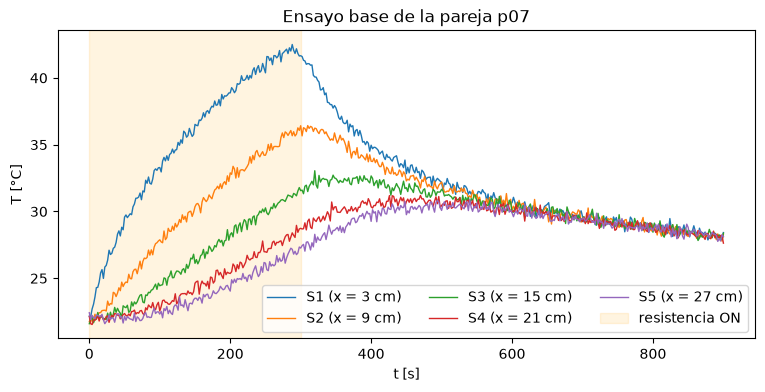

In [3]:
# ▶ Ejecuta: cargar el ensayo y dibujar los cinco sensores
datos = cargar_ensayo(CSV)
print(f"T_amb = {datos.T_amb:.2f} °C   ΔT_ref = {datos.DT_REF:.2f} K   muestras por sensor = {len(datos.df)}")

fig, ax = plt.subplots(figsize=(9, 4))
for s in SENSORES_VISIBLES:
    t, T = datos.serie(s); ax.plot(t, T, lw=1, label=f"{s} (x = {100*X_SENS[s]:.0f} cm)")
ax.axvspan(0, T_ON, color="orange", alpha=0.12, label="resistencia ON")
ax.set(xlabel="t [s]", ylabel="T [°C]", title=f"Ensayo base de la pareja {PAREJA}"); ax.legend(ncol=3); plt.show()

**Observa.** El sensor S1, a 3 cm de la resistencia, sube deprisa; S5, a 27 cm, apenas se entera. A los 300 s la
resistencia se apaga y todo empieza a enfriarse hacia la temperatura ambiente. Ese comportamiento —cuánto tarda
el calor en recorrer la barra y cuánto se pierde al aire— es lo que la ecuación del calor describe.

**Anota en la memoria:** la gráfica, T_amb, ΔT_ref y el instante en que S3 (15 cm) empieza a subir claramente.

✅ **Punto de control:** existe `data/<pareja>_base.csv`, tiene 451 filas y la gráfica muestra cinco curvas con un máximo entre 40 y 45 °C.

## Paso 1 · Una red neuronal «a secas» (30 min)

**Qué vais a hacer.** Entrenar una red neuronal normal (un MLP) que reciba una posición y un instante y devuelva
la temperatura. Pero con una trampa: **solo le enseñaréis los primeros 300 s**, cuando la resistencia está
encendida. Después le pediréis que prediga los 600 s siguientes.

> La pregunta que responde este paso: *¿puede una red que solo ha visto datos saber que la resistencia se apaga?*

### Antes de entrenar: números de orden 1
Una red neuronal se entrena mal con segundos, metros y grados mezclados. Por eso el módulo trabaja con variables
**adimensionales** (todas entre 0 y 1):

$$x^* = \frac{x}{L}, \qquad t^* = \frac{t}{T_{ref}}, \qquad u = \frac{T - T_{amb}}{\Delta T_{ref}}$$

con $L = 0{,}30$ m, $T_{ref} = 900$ s y $\Delta T_{ref}$ el mayor incremento de temperatura observado.
`datos.x`, `datos.t` y `datos.u` ya están en estas unidades; `predecir()` deshace el cambio para daros grados.

In [4]:
# ▶ Ejecuta: quedarnos solo con los primeros 300 s (misma escala que el ensayo completo)
datos_300 = cargar_ensayo(CSV, t_max=300, como=datos)
print(f"entrenaremos con {len(datos_300.df)} instantes × 5 sensores = {len(datos_300.u)} lecturas")

entrenaremos con 151 instantes × 5 sensores = 755 lecturas


In [ ]:
class MiMLP(torch.nn.Module):
    def __init__(self, ancho=64):
        super().__init__()
        torch.manual_seed(0)
        self.red = torch.nn.Sequential(
            torch.nn.Linear(2, ancho), torch.nn.Tanh(),
            torch.nn.Linear(ancho, ancho), torch.nn.Tanh(),
            torch.nn.Linear(ancho, ancho), torch.nn.Tanh(),
            torch.nn.Linear(ancho, 1)
        )
    def forward(self, x, t):
        return self.red(torch.cat([x, t], dim=1))

mlp = MiMLP()
opt = torch.optim.Adam(mlp.parameters(), lr=2e-3)

for it in range(3000):
    opt.zero_grad()
    pred = mlp(datos_300.x, datos_300.t)
    perdida = ((pred - datos_300.u) ** 2).mean()
    perdida.backward()
    opt.step()



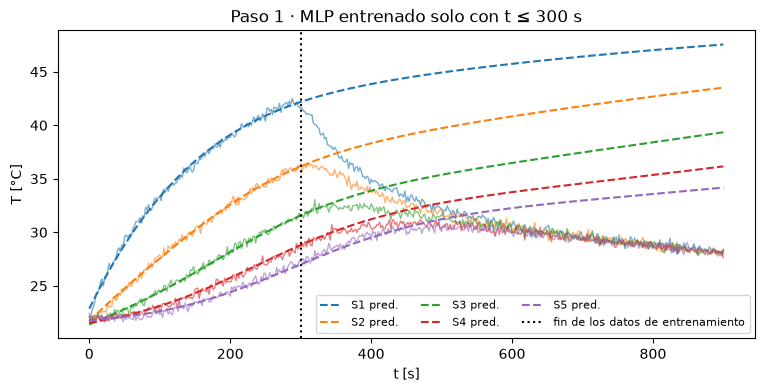

RMSE [°C] por ventanas de 150 s: [ 0.3   0.28  3.81  7.5   9.99 12.03]


In [6]:
# ▶ Ejecuta: comparar la predicción con lo que de verdad ocurrió (los 900 s)
def comparar(modelo, titulo):
    fig, ax = plt.subplots(figsize=(9, 4))
    for s in SENSORES_VISIBLES:
        t, T = datos.serie(s); l, = ax.plot(t, T, lw=1, alpha=.6)
        ax.plot(t, predecir(modelo, datos, [X_SENS[s]], t)[:, 0], "--", color=l.get_color(), label=f"{s} pred.")
    ax.axvline(300, color="k", ls=":", label="fin de los datos de entrenamiento")
    ax.set(xlabel="t [s]", ylabel="T [°C]", title=titulo); ax.legend(ncol=3, fontsize=8); plt.show()
    c, e = error_por_ventanas(modelo, datos, ancho_s=150)
    print("RMSE [°C] por ventanas de 150 s:", np.round(e, 2))
    return e

rmse_mlp = comparar(mlp, "Paso 1 · MLP entrenado solo con t ≤ 300 s")

**Observa.** Hasta 300 s la red clava los datos. A partir de ahí sigue «calentando» la barra: no tiene ninguna
forma de saber que la resistencia se ha apagado. No es un fallo de programación, es que **una red solo con datos
no puede predecir lo que nunca ha visto**.

**Anota en la memoria:** la gráfica y el RMSE de las ventanas 300-900 s (el de la última debería ser > 10 °C).

✅ **Punto de control:** RMSE de las dos primeras ventanas ≈ 0,3 °C y de la última > 5 °C.

## Paso 2 · La red que conoce la ecuación del calor (45 min)

**Qué vais a hacer.** Convertir esa red en una **PINN**: la misma red, pero con una pérdida que castiga a la red
cuando su salida **no cumple la ecuación del calor**. La ecuación, para una barra delgada con pérdidas al aire y
una resistencia que aporta calor, es

$$\frac{\partial T}{\partial t} = \alpha\,\frac{\partial^2 T}{\partial x^2} \;-\; h\,(T - T_{amb}) \;+\; q(x,t)$$

| Símbolo | Qué es | Lo conoce el gemelo |
|---|---|---|
| $\alpha$ | difusividad térmica: a qué velocidad viaja el calor por la barra (m²/s) | de tablas (por ahora) |
| $h$ | pérdidas al aire por unidad de capacidad térmica (1/s) | de tablas (por ahora) |
| $q(x,t)$ | calor que aporta la resistencia: 2,5 W en los primeros 2 cm, de 0 a 300 s (K/s) | **sí**, exactamente |

En variables adimensionales queda $\;\partial_{t^*} u = a\,\partial_{x^*x^*} u - b\,u + s(x^*,t^*)\;$ con
$a = \alpha T_{ref}/L^2$ y $b = h\,T_{ref}$.

La pérdida de la PINN suma tres términos:

$$\mathcal{L} = \lambda_{dat}\,\underbrace{\overline{(u_{NN}-u_{sensor})^2}}_{\text{datos}} \;+\; \lambda_{pde}\,\underbrace{\overline{\left(\partial_{t^*}u_{NN} - a\,\partial_{x^*x^*}u_{NN} + b\,u_{NN} - s\right)^2}}_{\text{residuo de la EDP en 4000 puntos al azar}} \;+\; \lambda_{bc}\,\underbrace{\overline{(\partial_{x^*}u_{NN})^2\big|_{x^*=0,1}}}_{\text{extremos aislados}}$$

Las derivadas las calcula PyTorch con **diferenciación automática** (`torch.autograd.grad`): mirad `PINN.residuo` en `pinn_barra.py`.
La condición inicial (barra a temperatura ambiente) no necesita término: la red devuelve $t^*\cdot NN(x^*,t^*)$, que vale 0 en $t^*=0$ por construcción.

Mismo experimento que en el paso 1: **entrenar solo con t ≤ 300 s**, con α y h «de manual» (aluminio, aire en calma).

In [7]:
# ▶ Ejecuta: la fuente conocida y los valores de manual
s0 = amplitud_fuente(datos)              # amplitud adimensional de q(x,t): 2,5 W en 2 cm de barra de Ø10 mm
a_tab, b_tab = valores_de_tablas()       # aluminio: alpha = 9,7e-5 m²/s ; aire en calma: h_conv = 8 W/m²K
print(f"s0 = {s0:.1f}   a_tab = {a_tab:.3f}   b_tab = {b_tab:.3f}")

s0 = 28.9   a_tab = 0.970   b_tab = 1.185


Adam     0  L=2.83e-01  dat=1.53e-01  pde=4.96e-02  bc=8.07e-02  a=0.970 b=1.185  (0s)
Adam   500  L=3.40e-03  dat=8.95e-04  pde=2.47e-03  bc=3.96e-05  a=0.970 b=1.185  (14s)
Adam  1000  L=1.76e-03  dat=3.82e-04  pde=1.35e-03  bc=3.03e-05  a=0.970 b=1.185  (29s)
Adam  1500  L=1.37e-03  dat=2.87e-04  pde=1.07e-03  bc=2.15e-05  a=0.970 b=1.185  (41s)
Adam  1999  L=1.28e-03  dat=2.69e-04  pde=9.91e-04  bc=1.98e-05  a=0.970 b=1.185  (53s)
L-BFGS      L=6.82e-04  dat=1.77e-04  pde=4.85e-04  a=0.970 b=1.185  (59s)


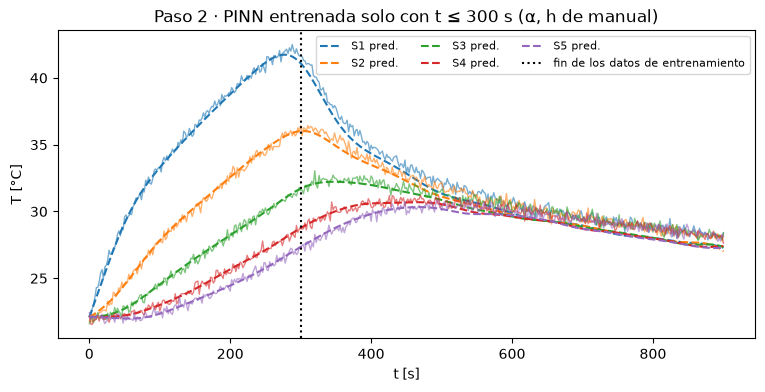

RMSE [°C] por ventanas de 150 s: [0.26 0.28 0.42 0.61 0.7  0.84]


In [8]:
# ▶ Ejecuta (≈ 1 min): PINN directa, entrenada SOLO con t ≤ 300 s
pinn_dir = PINN(inverso=False, a=a_tab, b=b_tab, s0=s0)
hist = entrenar(pinn_dir, datos_300, n_adam=2000, n_lbfgs=200, lam_pde=1.0, lam_bc=1.0)
rmse_pinn = comparar(pinn_dir, "Paso 2 · PINN entrenada solo con t ≤ 300 s (α, h de manual)")

**Observa.** La PINN **predice el enfriamiento sin haberlo visto nunca**. La ecuación le dice que, cuando la
fuente se apaga, el calor se reparte por la barra y se pierde al aire. Ese es el salto de «ajustar curvas» a
«gemelo digital».

### 👁️ El sensor virtual
El punto más caliente (junto a la resistencia, x = 1 cm) **no tiene sensor**: en una máquina real es justo donde
no se puede instrumentar. El fichero guarda un sexto sensor **oculto** en x = 1 cm que solo usamos para comprobar
si el gemelo acierta donde no ha visto nada.

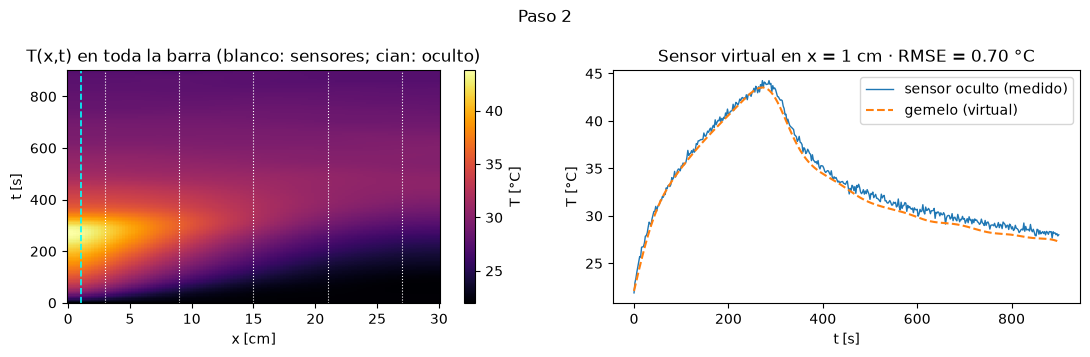

In [9]:
# ▶ Ejecuta: el campo completo T(x,t) y la comprobación con el sensor oculto
def mapa_y_sensor_virtual(modelo, titulo):
    x_m = np.linspace(0, L, 121); t_s = np.arange(0, 901, 5)
    campo = predecir(modelo, datos, x_m, t_s)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    im = ax[0].pcolormesh(x_m * 100, t_s, campo, shading="auto", cmap="inferno"); plt.colorbar(im, ax=ax[0], label="T [°C]")
    for s in SENSORES_VISIBLES: ax[0].axvline(100 * X_SENS[s], color="w", ls=":", lw=.8)
    ax[0].axvline(100 * X_SENS[SENSOR_OCULTO], color="cyan", ls="--", lw=1.2)
    ax[0].set(xlabel="x [cm]", ylabel="t [s]", title="T(x,t) en toda la barra (blanco: sensores; cian: oculto)")
    rmse, T_pred = error_sensor(modelo, datos); t, T_oc = datos.serie(SENSOR_OCULTO)
    ax[1].plot(t, T_oc, lw=1, label="sensor oculto (medido)"); ax[1].plot(t, T_pred, "--", label="gemelo (virtual)")
    ax[1].set(xlabel="t [s]", ylabel="T [°C]", title=f"Sensor virtual en x = 1 cm · RMSE = {rmse:.2f} °C"); ax[1].legend()
    fig.suptitle(titulo); plt.tight_layout(); plt.show()
    return rmse

rmse_virtual = mapa_y_sensor_virtual(pinn_dir, "Paso 2")

**Anota en la memoria:** la gráfica de predicción, el RMSE por ventanas (comparadlo con el del paso 1), el mapa
T(x,t) y el RMSE del sensor virtual.

### 🔬 Explorad (una prueba cada vez; 1 min por entrenamiento)
Copiad la celda de la PINN directa y cambiad **un** parámetro. Escribid una frase por prueba en la memoria.
1. `lam_pde=0.01` → ¿la red vuelve a comportarse como el MLP del paso 1? ¿Por qué?
2. `lam_pde=100` → ¿se ajusta peor a los sensores? ¿Qué está priorizando?
3. `PINN(..., fourier=False)` → los rasgos de Fourier son la receta estándar contra el sesgo espectral.
   ¿Cuánto cambia aquí el error, cerca de la resistencia y en el conjunto? ¿Estaban justificados en este problema?
4. `a=1.5*a_tab` → si la física que le dais es errónea, ¿a quién hace caso la red, a los datos o a la ecuación?

✅ **Punto de control:** RMSE por ventanas de la PINN < 1 °C en las seis ventanas (frente a > 10 °C del MLP) y RMSE del sensor virtual < 1 °C. Si el error crece poco a poco hacia el final es normal: α y h «de manual» no son exactamente los de vuestra barra. Eso lo arregla el paso 3.

--- Prueba 1: lam_pde = 0.01 ---
Adam     0  L=2.34e-01  dat=1.53e-01  pde=4.96e-02  bc=8.07e-02  a=0.970 b=1.185  (0s)
Adam   500  L=1.16e-03  dat=8.39e-04  pde=3.08e-02  bc=1.51e-05  a=0.970 b=1.185  (16s)
Adam  1000  L=7.00e-04  dat=4.31e-04  pde=2.31e-02  bc=3.86e-05  a=0.970 b=1.185  (34s)
Adam  1500  L=5.04e-04  dat=3.16e-04  pde=1.85e-02  bc=2.61e-06  a=0.970 b=1.185  (50s)
Adam  1999  L=4.63e-04  dat=2.91e-04  pde=1.70e-02  bc=2.03e-06  a=0.970 b=1.185  (67s)
L-BFGS      L=2.53e-04  dat=1.83e-04  pde=6.59e-03  a=0.970 b=1.185  (76s)


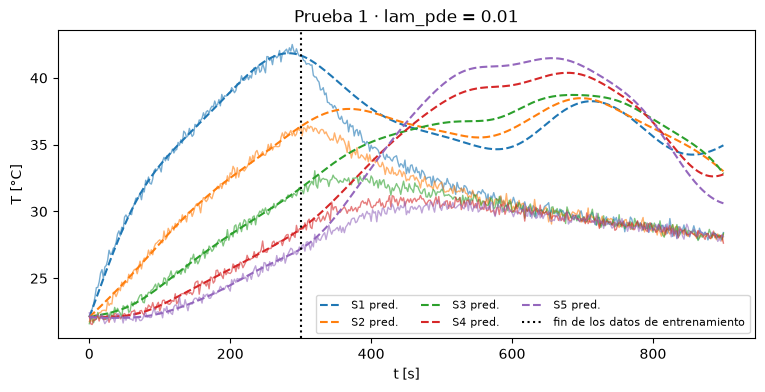

RMSE [°C] por ventanas de 150 s: [0.29 0.27 2.75 6.6  9.29 7.01]
--- Prueba 2: lam_pde = 100 ---
Adam     0  L=5.19e+00  dat=1.53e-01  pde=4.96e-02  bc=8.07e-02  a=0.970 b=1.185  (0s)
Adam   500  L=5.50e-02  dat=7.49e-04  pde=5.00e-04  bc=4.20e-03  a=0.970 b=1.185  (20s)
Adam  1000  L=3.15e-02  dat=4.39e-04  pde=2.81e-04  bc=2.99e-03  a=0.970 b=1.185  (36s)
Adam  1500  L=2.20e-02  dat=3.98e-04  pde=1.95e-04  bc=2.08e-03  a=0.970 b=1.185  (52s)
Adam  1999  L=1.92e-02  dat=3.89e-04  pde=1.70e-04  bc=1.83e-03  a=0.970 b=1.185  (64s)
L-BFGS      L=7.09e-03  dat=4.24e-04  pde=6.13e-05  a=0.970 b=1.185  (71s)


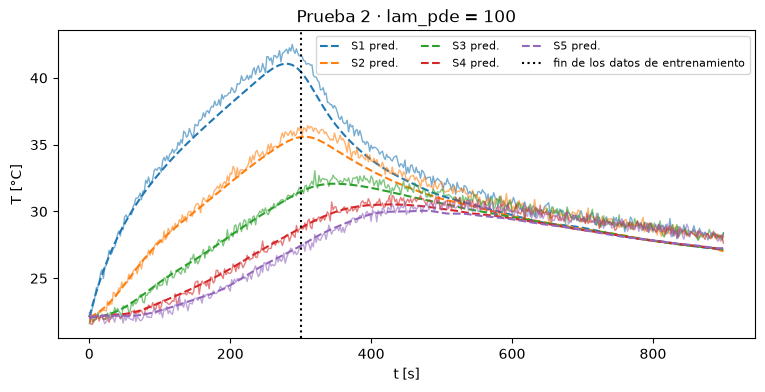

RMSE [°C] por ventanas de 150 s: [0.31 0.51 0.68 0.77 0.85 0.97]
--- Prueba 3: fourier = False ---
Adam     0  L=1.93e-01  dat=1.59e-01  pde=3.34e-02  bc=7.92e-04  a=0.970 b=1.185  (0s)
Adam   500  L=4.17e-03  dat=6.61e-04  pde=3.40e-03  bc=1.02e-04  a=0.970 b=1.185  (10s)
Adam  1000  L=3.17e-03  dat=6.17e-04  pde=2.47e-03  bc=8.17e-05  a=0.970 b=1.185  (20s)
Adam  1500  L=2.44e-03  dat=5.36e-04  pde=1.83e-03  bc=7.36e-05  a=0.970 b=1.185  (30s)
Adam  1999  L=2.16e-03  dat=4.84e-04  pde=1.61e-03  bc=6.18e-05  a=0.970 b=1.185  (39s)
L-BFGS      L=7.33e-04  dat=2.08e-04  pde=5.01e-04  a=0.970 b=1.185  (43s)


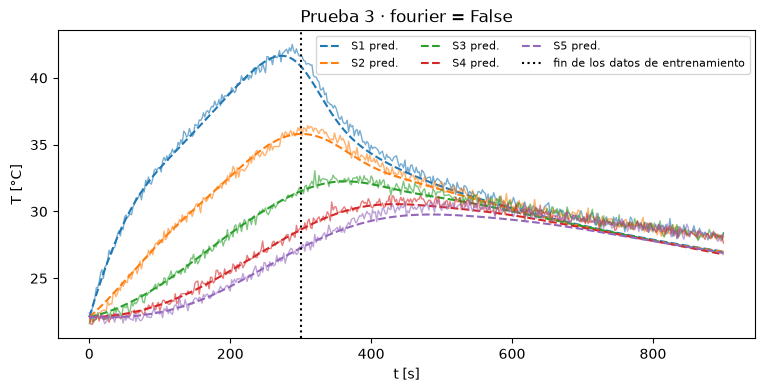

RMSE [°C] por ventanas de 150 s: [0.28 0.31 0.47 0.47 0.65 1.03]


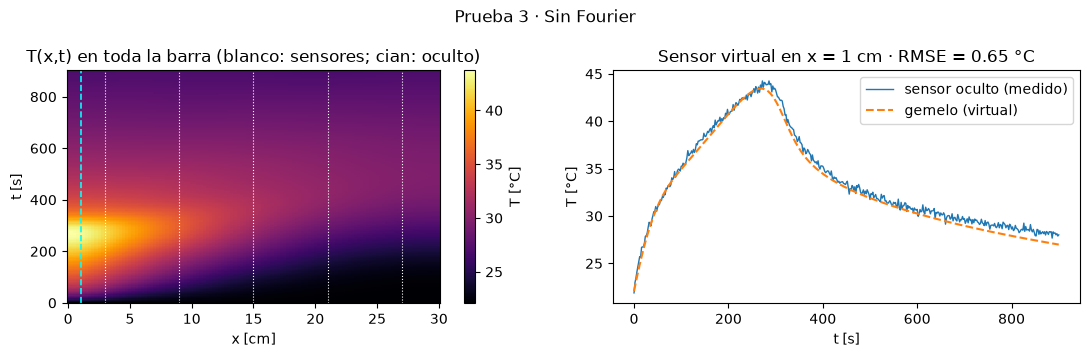

--- Prueba 4: a = 1.5 * a_tab ---
Adam     0  L=2.99e-01  dat=1.53e-01  pde=6.53e-02  bc=8.07e-02  a=1.455 b=1.185  (0s)
Adam   500  L=3.90e-03  dat=1.31e-03  pde=2.53e-03  bc=6.13e-05  a=1.455 b=1.185  (16s)
Adam  1000  L=2.74e-03  dat=8.98e-04  pde=1.78e-03  bc=6.07e-05  a=1.455 b=1.185  (34s)
Adam  1500  L=2.37e-03  dat=7.79e-04  pde=1.54e-03  bc=5.31e-05  a=1.455 b=1.185  (52s)
Adam  1999  L=2.27e-03  dat=7.54e-04  pde=1.47e-03  bc=5.23e-05  a=1.455 b=1.185  (70s)
L-BFGS      L=1.70e-03  dat=6.48e-04  pde=1.00e-03  a=1.455 b=1.185  (80s)


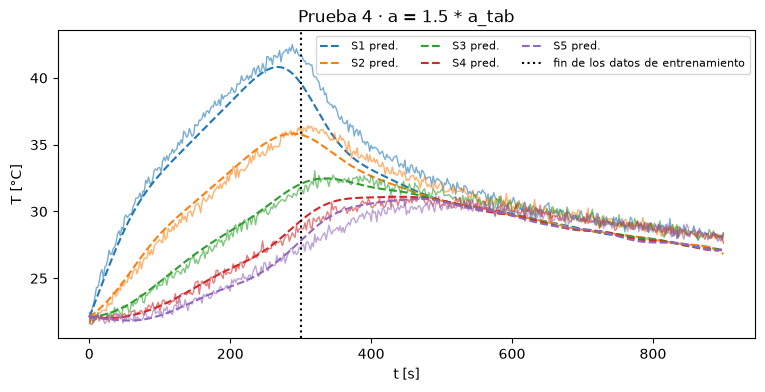

RMSE [°C] por ventanas de 150 s: [0.43 0.59 1.16 0.77 0.83 0.98]


In [ ]:

# 1. Pérdida física residual insignificante (lam_pde baja)
print("--- Prueba 1: lam_pde = 0.01 ---")
pinn_exp1 = PINN(inverso=False, a=a_tab, b=b_tab, s0=s0)
entrenar(pinn_exp1, datos_300, n_adam=2000, n_lbfgs=200, lam_pde=0.01, lam_bc=1.0)
rmse_exp1 = comparar(pinn_exp1, "Prueba 1 · lam_pde = 0.01")

# 2. Pérdida física dominante sobre los datos (lam_pde alta)
print("--- Prueba 2: lam_pde = 100 ---")
pinn_exp2 = PINN(inverso=False, a=a_tab, b=b_tab, s0=s0)
entrenar(pinn_exp2, datos_300, n_adam=2000, n_lbfgs=200, lam_pde=100.0, lam_bc=1.0)
rmse_exp2 = comparar(pinn_exp2, "Prueba 2 · lam_pde = 100")

# 3. Sin características de Fourier
print("--- Prueba 3: fourier = False ---")
pinn_exp3 = PINN(inverso=False, a=a_tab, b=b_tab, s0=s0, fourier=False)
entrenar(pinn_exp3, datos_300, n_adam=2000, n_lbfgs=200, lam_pde=1.0, lam_bc=1.0)
rmse_exp3 = comparar(pinn_exp3, "Prueba 3 · fourier = False")
mapa_y_sensor_virtual(pinn_exp3, "Prueba 3 · Sin Fourier")

# 4. Física errónea impuesta (difusividad 50% superior)
print("--- Prueba 4: a = 1.5 * a_tab ---")
pinn_exp4 = PINN(inverso=False, a=1.5 * a_tab, b=b_tab, s0=s0)
entrenar(pinn_exp4, datos_300, n_adam=2000, n_lbfgs=200, lam_pde=1.0, lam_bc=1.0)
rmse_exp4 = comparar(pinn_exp4, "Prueba 4 · a = 1.5 * a_tab")

## Paso 3 · El gemelo se calibra solo (casa · 1,5 h)

**Qué vais a hacer.** Hasta ahora α y h eran «de manual». Pero vuestra barra no es la del manual: la aleación,
el estado de la superficie o el contacto de los sensores cambian sus valores efectivos. Vais a convertir α y h en
**parámetros que la red aprende** junto con la temperatura (problema inverso), usando el ensayo completo.

Dos detalles de la receta, ya implementados en `pinn_barra.py` (leed `PINN.__init__` y `entrenar`):
- α y h se guardan como $\log a$ y $\log b$ (así nunca se hacen negativos) y se mantienen **congelados el primer 10 %**
  de las iteraciones, para que la red aprenda primero la forma de la solución;
- el residuo se divide por la amplitud de la fuente $s_0$, para que el término de la EDP sea un error **relativo**
  y no lo domine la zona de la resistencia.

Arrancamos deliberadamente lejos ($a = b = 0{,}5$) para ver cómo convergen.

In [ ]:

# Crear la PINN en modo inverso con a y b inicializados en 0.5
pinn_inv = PINN(inverso=True, a=0.5, b=0.5, s0=s0)

# Entrenar con el ensayo completo 'datos' (4000 pasos Adam + 300 pasos L-BFGS)
hist = entrenar(pinn_inv, datos, n_adam=4000, n_lbfgs=300)

# Extraer los parámetros físicos identificados
alpha_id, h_id = pinn_inv.parametros()

# Guardar el modelo calibrado para los pasos posteriores
guardar(pinn_inv, f"gemelo_{PAREJA}.pt")

Adam     0  L=2.61e-01  dat=1.41e-01  pde=3.92e-02  bc=8.07e-02  a=0.500 b=0.500  (0s)
Adam   500  L=3.73e-03  dat=7.68e-04  pde=2.92e-03  bc=3.59e-05  a=0.673 b=0.715  (13s)
Adam  1000  L=1.74e-03  dat=3.37e-04  pde=1.36e-03  bc=3.65e-05  a=0.952 b=0.858  (24s)
Adam  1500  L=1.18e-03  dat=2.25e-04  pde=9.32e-04  bc=2.43e-05  a=0.928 b=0.864  (36s)
Adam  2000  L=9.07e-04  dat=1.87e-04  pde=7.06e-04  bc=1.40e-05  a=0.913 b=0.881  (48s)
Adam  2500  L=7.68e-04  dat=1.74e-04  pde=5.86e-04  bc=9.14e-06  a=0.906 b=0.895  (63s)
Adam  3000  L=6.88e-04  dat=1.67e-04  pde=5.14e-04  bc=7.06e-06  a=0.903 b=0.904  (77s)
Adam  3500  L=6.45e-04  dat=1.64e-04  pde=4.75e-04  bc=6.21e-06  a=0.901 b=0.908  (92s)
Adam  3999  L=6.22e-04  dat=1.63e-04  pde=4.53e-04  bc=5.82e-06  a=0.901 b=0.910  (107s)
L-BFGS      L=3.13e-04  dat=1.53e-04  pde=1.54e-04  a=0.864 b=0.924  (121s)


α de vuestra barra = 8.641e-05 m²/s   (manual: 9.700e-05, -10.9 %)
h de vuestra barra = 1.026e-03 1/s    (manual: 1.317e-03, -22.1 %)
RMSE del sensor virtual = 0.26 °C


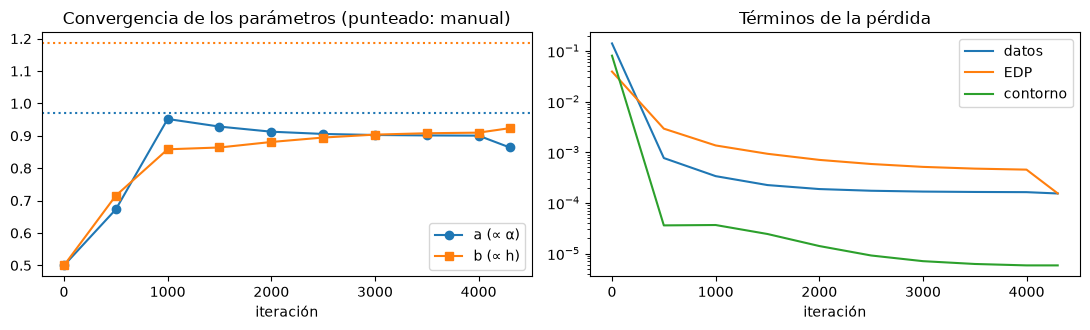

gemelo calibrado guardado en gemelo_p07.pt


In [13]:
# ▶ Ejecuta: resultados de la identificación
alpha_id, h_id = pinn_inv.parametros()
alpha_tab, h_tab = dimensional(a_tab, b_tab)
print(f"α de vuestra barra = {alpha_id:.3e} m²/s   (manual: {alpha_tab:.3e}, {100*(alpha_id/alpha_tab-1):+.1f} %)")
print(f"h de vuestra barra = {h_id:.3e} 1/s    (manual: {h_tab:.3e}, {100*(h_id/h_tab-1):+.1f} %)")
print(f"RMSE del sensor virtual = {error_sensor(pinn_inv, datos)[0]:.2f} °C")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(hist["it"], hist["a"], "o-", label="a (∝ α)"); ax[0].plot(hist["it"], hist["b"], "s-", label="b (∝ h)")
ax[0].axhline(a_tab, ls=":", color="C0"); ax[0].axhline(b_tab, ls=":", color="C1")
ax[0].set(title="Convergencia de los parámetros (punteado: manual)", xlabel="iteración"); ax[0].legend()
ax[1].semilogy(hist["it"], hist["L_dat"], label="datos"); ax[1].semilogy(hist["it"], hist["L_pde"], label="EDP"); ax[1].semilogy(hist["it"], hist["L_bc"], label="contorno")
ax[1].set(title="Términos de la pérdida", xlabel="iteración"); ax[1].legend(); plt.tight_layout(); plt.show()

guardar(pinn_inv, f"gemelo_{PAREJA}.pt"); print(f"gemelo calibrado guardado en gemelo_{PAREJA}.pt")

**Observa.** Durante el primer 10 % los parámetros no se mueven (están congelados); después convergen en unas
1 500 iteraciones y L-BFGS los afina. Los valores identificados son los de **vuestra** barra: distintos de los
de manual y distintos de los de la pareja de al lado.

**Anota en la memoria:** las dos gráficas, α y h con sus unidades y el porcentaje de diferencia respecto al manual.
Explicad con vuestras palabras por qué un gemelo debe aprender los valores *efectivos* de su activo en lugar de fiarse del manual.

✅ **Punto de control:** α entre 8·10⁻⁵ y 1,1·10⁻⁴ m²/s, RMSE del sensor virtual < 0,4 °C.

## Paso 4 · ¿Cuánto me fío? (casa · 1 h)

**Qué vais a hacer.** Un parámetro sin barra de error no sirve para decidir nada. Vais a estimar la dispersión de
α y h de tres maneras. Para acortar, usad `n_adam=2500, n_lbfgs=200` (≈ 1,5 min cada entrenamiento).

| Prueba | Qué cambia | Cómo |
|---|---|---|
| A. Semillas | la inicialización de la red | `PINN(..., seed=0)`, `seed=1`, `seed=2` |
| B. Ruido | sensores peores | `datos_ruido.u += torch.randn_like(datos_ruido.u) * 0.5 / datos_ruido.DT_REF` (0,5 °C; repetid con 1,0) |
| C. Menos sensores | quitar S2 y S4 | `cargar_ensayo(CSV, sensores=["S1", "S3", "S5"])` |

In [ ]:

res_A = []

for s in [0, 1, 2]:
    print(f"\n--- Entrenando con seed = {s} ---")
    pinn_s = PINN(inverso=True, a=0.5, b=0.5, s0=s0, seed=s)
    entrenar(pinn_s, datos, n_adam=2500, n_lbfgs=200)
    alpha_s, h_s = pinn_s.parametros()
    res_A.append((alpha_s, h_s))
    print(f"Semilla {s} -> alpha: {alpha_s:.3e} m²/s, h: {h_s:.3e} 1/s")

# Extraer arreglos para calcular media y desviación típica
alphas_A = np.array([r[0] for r in res_A])
hs_A = np.array([r[1] for r in res_A])

print("\nResultados Prueba A (Semillas):")
print(f"alpha: {alphas_A.mean():.3e} ± {alphas_A.std():.3e} m²/s")
print(f"h:     {hs_A.mean():.3e} ± {hs_A.std():.3e} 1/s")


--- Entrenando con seed = 0 ---
Adam     0  L=2.61e-01  dat=1.41e-01  pde=3.92e-02  bc=8.07e-02  a=0.500 b=0.500  (0s)
Adam   500  L=3.35e-03  dat=6.34e-04  pde=2.67e-03  bc=4.07e-05  a=0.829 b=0.963  (13s)
Adam  1000  L=1.86e-03  dat=3.50e-04  pde=1.42e-03  bc=9.76e-05  a=0.954 b=0.861  (24s)
Adam  1500  L=1.28e-03  dat=2.33e-04  pde=1.02e-03  bc=2.57e-05  a=0.930 b=0.862  (37s)
Adam  2000  L=1.10e-03  dat=2.05e-04  pde=8.74e-04  bc=2.29e-05  a=0.920 b=0.868  (52s)
Adam  2499  L=1.04e-03  dat=1.97e-04  pde=8.24e-04  bc=2.13e-05  a=0.918 b=0.870  (68s)
L-BFGS      L=5.94e-04  dat=1.68e-04  pde=4.13e-04  a=0.851 b=0.874  (74s)
Semilla 0 -> alpha: 8.509e-05 m²/s, h: 9.712e-04 1/s

--- Entrenando con seed = 1 ---
Adam     0  L=2.98e-01  dat=2.23e-01  pde=3.50e-02  bc=4.01e-02  a=0.500 b=0.500  (0s)
Adam   500  L=2.89e-03  dat=5.69e-04  pde=2.27e-03  bc=4.85e-05  a=0.875 b=0.961  (15s)
Adam  1000  L=1.58e-03  dat=2.78e-04  pde=1.11e-03  bc=1.91e-04  a=0.965 b=0.853  (31s)
Adam  1500  L=1.

In [ ]:

import copy

# ==========================================
# PRUEBA B: Ruido añadido (0.5 °C y 1.0 °C)
# ==========================================
resultados_ruido = {}

for nivel_ruido in [0.5, 1.0]:
    print(f"--- Evaluando Prueba B (Ruido ±{nivel_ruido} °C) ---")
    res_b = []
    
    for s in [0, 1, 2]:
        torch.manual_seed(s)
        # Clonar datos para no sobreescribir el objeto original
        datos_ruido = copy.deepcopy(datos)
        # Inyectar ruido gaussiano escalado a las unidades adimensionales
        ruido_adimensional = torch.randn_like(datos_ruido.u) * (nivel_ruido / datos_ruido.DT_REF)
        datos_ruido.u += ruido_adimensional
        
        pinn_b = PINN(inverso=True, a=0.5, b=0.5, s0=s0, seed=s)
        entrenar(pinn_b, datos_ruido, n_adam=2500, n_lbfgs=200)
        alpha_b, h_b = pinn_b.parametros()
        res_b.append((alpha_b, h_b))
        print(f"Ruido {nivel_ruido} °C (seed {s}) -> alpha: {alpha_b:.3e} m²/s, h: {h_b:.3e} 1/s")
        
    alphas_b = np.array([r[0] for r in res_b])
    hs_b = np.array([r[1] for r in res_b])
    resultados_ruido[nivel_ruido] = (alphas_b, hs_b)

# PRUEBA C: Menos sensores (quitar S2 y S4)
print(f"--- Evaluando Prueba C (Menos sensores: S1, S3, S5) ---")
datos_reducidos = cargar_ensayo(CSV, sensores=["S1", "S3", "S5"])
res_c = []

for s in [0, 1, 2]:
    pinn_c = PINN(inverso=True, a=0.5, b=0.5, s0=s0, seed=s)
    entrenar(pinn_c, datos_reducidos, n_adam=2500, n_lbfgs=200)
    alpha_c, h_c = pinn_c.parametros()
    res_c.append((alpha_c, h_c))
    print(f"3 Sensores (seed {s}) -> alpha: {alpha_c:.3e} m²/s, h: {h_c:.3e} 1/s")

alphas_c = np.array([r[0] for r in res_c])
hs_c = np.array([r[1] for r in res_c])

# TABLA RESUMEN PARA LA MEMORIA
print("\n" + "="*70)
print(f"{'Configuración':<30} | {'alpha [m²/s]':<18} | {'h [1/s]':<18}")
print("-" * 70)
print(f"{'A. Semillas base':<30} | {alphas_A.mean():.3e} ± {alphas_A.std():.3e} | {hs_A.mean():.3e} ± {hs_A.std():.3e}")
for nr in [0.5, 1.0]:
    a_m, a_s = resultados_ruido[nr][0].mean(), resultados_ruido[nr][0].std()
    h_m, h_s = resultados_ruido[nr][1].mean(), resultados_ruido[nr][1].std()
    print(f"{f'B. Ruido {nr} °C':<30} | {a_m:.3e} ± {a_s:.3e} | {h_m:.3e} ± {h_s:.3e}")
print(f"{'C. Menos sensores (S1,S3,S5)':<30} | {alphas_c.mean():.3e} ± {alphas_c.std():.3e} | {hs_c.mean():.3e} ± {hs_c.std():.3e}")
print("="*70)


--- Evaluando Prueba B (Ruido ±0.5 °C) ---
Adam     0  L=2.62e-01  dat=1.42e-01  pde=3.92e-02  bc=8.07e-02  a=0.500 b=0.500  (0s)
Adam   500  L=4.48e-03  dat=1.24e-03  pde=2.63e-03  bc=6.07e-04  a=0.839 b=0.956  (13s)
Adam  1000  L=2.38e-03  dat=9.46e-04  pde=1.39e-03  bc=3.72e-05  a=0.964 b=0.844  (26s)
Adam  1500  L=1.87e-03  dat=8.29e-04  pde=1.02e-03  bc=2.57e-05  a=0.926 b=0.866  (45s)
Adam  2000  L=1.69e-03  dat=7.99e-04  pde=8.71e-04  bc=2.23e-05  a=0.914 b=0.875  (62s)
Adam  2499  L=1.63e-03  dat=7.90e-04  pde=8.21e-04  bc=2.06e-05  a=0.912 b=0.878  (77s)
L-BFGS      L=1.19e-03  dat=7.57e-04  pde=4.23e-04  a=0.849 b=0.882  (84s)
Ruido 0.5 °C (seed 0) -> alpha: 8.494e-05 m²/s, h: 9.805e-04 1/s
Adam     0  L=3.00e-01  dat=2.25e-01  pde=3.50e-02  bc=4.01e-02  a=0.500 b=0.500  (0s)
Adam   500  L=3.45e-03  dat=1.17e-03  pde=2.23e-03  bc=4.81e-05  a=0.894 b=0.954  (15s)
Adam  1000  L=2.01e-03  dat=8.84e-04  pde=1.10e-03  bc=2.37e-05  a=0.961 b=0.851  (30s)
Adam  1500  L=1.63e-03  da

**Anota en la memoria:** una tabla con media ± desviación de α y h para A, B (0,5 y 1,0 °C) y C, y una
conclusión de una frase: ¿qué degrada más la identificación, el ruido o la falta de sensores?

✅ **Punto de control:** la desviación entre semillas es mucho menor (≈ 1 %) que la diferencia con el manual.

## Paso 5 · Reto: la planta cambia (hasta 7 puntos)

**Qué vais a hacer.** El gemelo está calibrado y guardado. Ahora **alguien enciende un ventilador** junto a la
barra: las pérdidas al aire se multiplican. Un gemelo digital de verdad debe

1. 🚨 **darse cuenta** de que sus predicciones ya no cuadran con la planta,
2. 🎚️ **recalibrarse** con pocos datos y sin empezar de cero,
3. 📢 **publicar** su estado para que el resto del sistema lo vea.

Empezad haciendo el nuevo ensayo con la planta virtual (también podéis probar `"aislante"`).

Barra de la pareja p07 · ensayo «ventilador»
Encendiendo la resistencia (2,5 W) ... ■■■■■□□□□□□□□□□  15 min simulados
Ensayo guardado en data/p07_ventilador.csv  (T máxima leída: 40.5 °C)


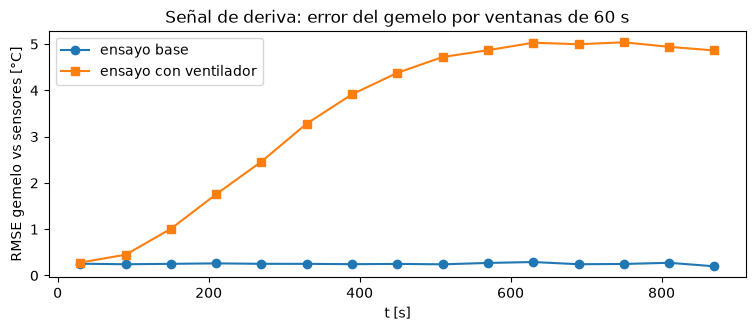

In [16]:
# ▶ Ejecuta: nuevo ensayo con ventilador y carga con la escala del gemelo base
CSV_der = planta_virtual.ensayo(PAREJA, "ventilador")
datos_der = cargar_ensayo(CSV_der, como=datos)

gemelo = cargar(PINN(inverso=True, a=0.5, b=0.5, s0=s0), f"gemelo_{PAREJA}.pt")
c, e_base = error_por_ventanas(gemelo, datos, ancho_s=60)        # el gemelo frente al ensayo con el que se calibró
c, e_der = error_por_ventanas(gemelo, datos_der, ancho_s=60)     # el mismo gemelo frente al ensayo con ventilador
plt.figure(figsize=(9, 3.2)); plt.plot(c, e_base, "o-", label="ensayo base"); plt.plot(c, e_der, "s-", label="ensayo con ventilador")
plt.xlabel("t [s]"); plt.ylabel("RMSE gemelo vs sensores [°C]"); plt.title("Señal de deriva: error del gemelo por ventanas de 60 s"); plt.legend(); plt.show()

**Observa.** Sobre el ensayo base el error se queda en el nivel del ruido (≈ 0,25 °C). Sobre el ensayo con
ventilador el error crece minuto a minuto: el gemelo predice una barra más caliente de lo que miden los sensores.
Eso es la **señal de deriva**.

### ✏️ Vuestro trabajo en el reto
1. **Detector de deriva.** Definid un umbral (por ejemplo, tres veces el RMSE medio del ensayo base) y cuántas
   ventanas consecutivas por encima hacen falta para declarar «deriva». Justificadlo: ¿qué pasa con un umbral
   demasiado bajo? ¿Y con uno demasiado alto?
2. **Recalibración.** Partid del gemelo guardado y reentrenad **solo unas pocas iteraciones** con los datos nuevos
   (`congelar_frac=0`, `n_adam=1000`, `n_lbfgs=200`). Comparad tiempo y resultado con entrenar desde cero
   (`PINN(inverso=True, a=0.5, b=0.5, s0=s0)` + `n_adam=4000`).
3. **Publicación.** Guardad el estado del gemelo en `estado_gemelo_<pareja>.json` con `alpha`, `h`, `rmse`,
   `estado` (`ok` / `deriva` / `recalibrado`) y `t_alarma_s`, y dibujad el «panel» de la celda final. Si tenéis
   la pila MQTT del curso en marcha, publicadlo también en `lab/barra/<pareja>/gemelo` (celda opcional).

In [ ]:

# 1. DETECTOR DE DERIVA
umbral = 3.0 * float(np.mean(e_base))
N_CONSECUTIVAS = 2

consecutivas = 0
t_alarma = None

for centro_t, error in zip(c, e_der):
    if error > umbral:
        consecutivas += 1
        if consecutivas >= N_CONSECUTIVAS and t_alarma is None:
            t_alarma = float(centro_t)
    else:
        consecutivas = 0

print(f"Umbral de deriva: {umbral:.3f} °C")
print(f"Alarma de deriva declarada en: t = {t_alarma} s")

# 2. RECALIBRACIÓN DESDE EL GEMELO BASE GUARDADO
# Parámetros base del gemelo original
alpha_base, h_base = gemelo.parametros()

# Cargar y recalibrar con warm start sobre datos_der
gemelo_rec = cargar(PINN(inverso=True, a=0.5, b=0.5, s0=s0), f"gemelo_{PAREJA}.pt")
entrenar(gemelo_rec, datos_der, n_adam=1000, n_lbfgs=200, congelar_frac=0.0)

# Extraer parámetros y errores con los nombres que pide el cuaderno
alpha_rec, h_rec = gemelo_rec.parametros()
_, e_rec = error_por_ventanas(gemelo_rec, datos_der, ancho_s=60)

print(f"\nBase:        alpha = {alpha_base:.3e} m²/s, h = {h_base:.3e} 1/s")
print(f"Recalibrado: alpha = {alpha_rec:.3e} m²/s, h = {h_rec:.3e} 1/s")
print(f"RMSE medio después de recalibrar: {np.mean(e_rec):.3f} °C")

Umbral de deriva: 0.755 °C
Alarma de deriva declarada en: t = 210.0 s
Adam     0  L=3.63e-02  dat=3.61e-02  pde=1.54e-04  bc=5.82e-06  a=0.868 b=0.927  (0s)
Adam   500  L=4.33e-04  dat=1.98e-04  pde=2.28e-04  bc=7.72e-06  a=0.868 b=2.161  (23s)
Adam   999  L=3.55e-04  dat=1.70e-04  pde=1.79e-04  bc=6.47e-06  a=0.871 b=2.570  (45s)
L-BFGS      L=2.83e-04  dat=1.49e-04  pde=1.28e-04  a=0.884 b=2.763  (53s)

Base:        alpha = 8.641e-05 m²/s, h = 1.026e-03 1/s
Recalibrado: alpha = 8.843e-05 m²/s, h = 3.070e-03 1/s
RMSE medio después de recalibrar: 0.249 °C


{
 "pareja": "p07",
 "alpha": 8.842952847480773e-05,
 "h": 0.003069945706261529,
 "rmse": 0.24883674159652822,
 "estado": "recalibrado",
 "t_alarma_s": 210.0
}


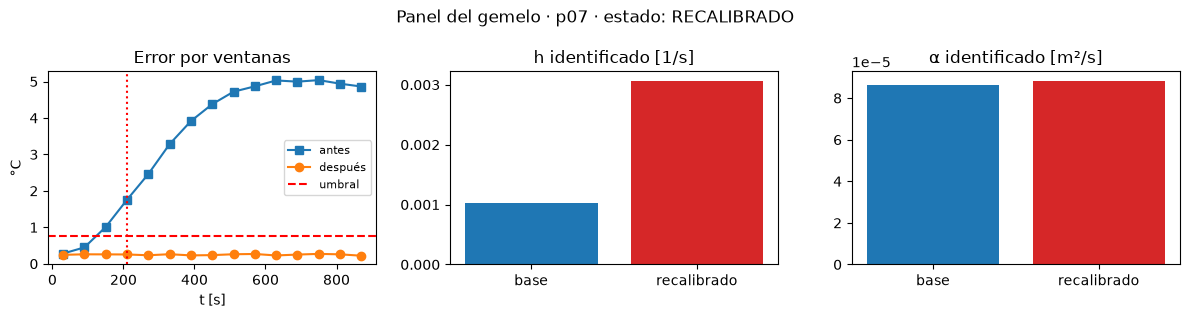

In [21]:
# ▶ Ejecuta: guardar el estado y dibujar el panel del gemelo
estado = {"pareja": PAREJA, "alpha": alpha_rec, "h": h_rec, "rmse": float(e_rec.mean()),
          "estado": "recalibrado", "t_alarma_s": t_alarma}
json.dump(estado, open(f"estado_gemelo_{PAREJA}.json", "w"), indent=1); print(json.dumps(estado, indent=1))

fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
ax[0].plot(c, e_der, "s-", label="antes"); ax[0].plot(c, e_rec, "o-", label="después"); ax[0].axhline(umbral, color="r", ls="--", label="umbral")
if t_alarma: ax[0].axvline(t_alarma, color="r", ls=":")
ax[0].set(title="Error por ventanas", xlabel="t [s]", ylabel="°C"); ax[0].legend(fontsize=8)
ax[1].bar(["base", "recalibrado"], [h_base, h_rec], color=["C0", "C3"]); ax[1].set(title="h identificado [1/s]")
ax[2].bar(["base", "recalibrado"], [alpha_base, alpha_rec], color=["C0", "C3"]); ax[2].set(title="α identificado [m²/s]")
fig.suptitle(f"Panel del gemelo · {PAREJA} · estado: {estado['estado'].upper()}"); plt.tight_layout(); plt.show()

In [22]:
# (opcional) publicar por MQTT si tenéis el broker del curso en marcha (docker compose up -d)
try:
    import paho.mqtt.client as mqtt
    cli = mqtt.Client(mqtt.CallbackAPIVersion.VERSION2) if hasattr(mqtt, "CallbackAPIVersion") else mqtt.Client()
    cli.connect("localhost", 1883, 5); cli.publish(f"lab/barra/{PAREJA}/gemelo", json.dumps(estado), retain=True); cli.disconnect()
    print("publicado en MQTT")
except Exception as ex:
    print("sin broker MQTT (no pasa nada, el JSON ya está guardado):", ex)

sin broker MQTT (no pasa nada, el JSON ya está guardado): No module named 'paho'


**Anota en la memoria:** la gráfica de deriva con el umbral, el instante de detección, la tabla antes/después
(α, h, RMSE, tiempo de entrenamiento) comparada con entrenar desde cero, y el panel.

✅ **Punto de control:** tras recalibrar, h ≈ 3 × el valor base (el ventilador triplica las pérdidas), α se mueve menos de un 5 % y el RMSE vuelve a ≈ 0,25 °C.

---
## Paso 6 · Súper reto (hasta 10 puntos) · elegid uno
- **(a) La barra misteriosa.** `planta_virtual.ensayo(PAREJA, misterio=True)` ensaya una barra de **otro metal**
  con el mismo montaje. Identificad α con su incertidumbre y decid qué metal es (tabla en la ficha). ¿Qué otros
  parámetros podrían confundir la identificación?
- **(b) La resistencia desconocida.** Hasta ahora el gemelo conocía la potencia. Repetid el paso 3 con
  `PINN(inverso=True, a=0.5, b=0.5, s0=s0, fuente_libre=True)`, que aprende también la amplitud de la fuente
  (`gemelo.amplitud_identificada()`), arrancando desde `0.6*s0` y desde `1.5*s0`. Comparad el ajuste y los valores
  de α, h y s₀ con los del paso 3. ¿Se pueden identificar los tres a la vez? ¿Qué medida adicional haría falta?
- **(c) La batería.** Dataset público NASA PCoE: circuito equivalente RC por ciclo y deriva de $R_0$ frente al número de ciclo.

Entrega: cuaderno + simulación + presentación de 5 minutos.

Barra de la pareja p07 · ensayo «misterio»
Encendiendo la resistencia (2,5 W) ... ■■■■■□□□□□□□□□□  15 min simulados
Ensayo guardado en data/p07_misterio.csv  (T máxima leída: 65.6 °C)
Entrenando problema inverso sobre la barra misteriosa...
Adam     0  L=2.08e-01  dat=8.01e-02  pde=4.73e-02  bc=8.07e-02  a=0.500 b=0.500  (0s)
Adam   500  L=2.74e-03  dat=5.01e-04  pde=2.21e-03  bc=2.53e-05  a=0.293 b=0.326  (15s)
Adam  1000  L=1.30e-03  dat=1.60e-04  pde=1.12e-03  bc=1.97e-05  a=0.224 b=0.570  (36s)
Adam  1500  L=8.04e-04  dat=7.84e-05  pde=7.20e-04  bc=5.61e-06  a=0.198 b=0.830  (59s)
Adam  2000  L=6.25e-04  dat=6.45e-05  pde=5.56e-04  bc=4.42e-06  a=0.192 b=0.895  (83s)
Adam  2500  L=5.41e-04  dat=6.03e-05  pde=4.77e-04  bc=3.98e-06  a=0.191 b=0.907  (111s)
Adam  2999  L=5.06e-04  dat=5.88e-05  pde=4.43e-04  bc=3.81e-06  a=0.191 b=0.909  (137s)
L-BFGS      L=1.70e-04  dat=5.45e-05  pde=1.12e-04  a=0.187 b=0.928  (150s)
Semilla 0 -> alpha: 1.868e-05 m²/s, h: 1.032e-03 1/s
Adam     0  L

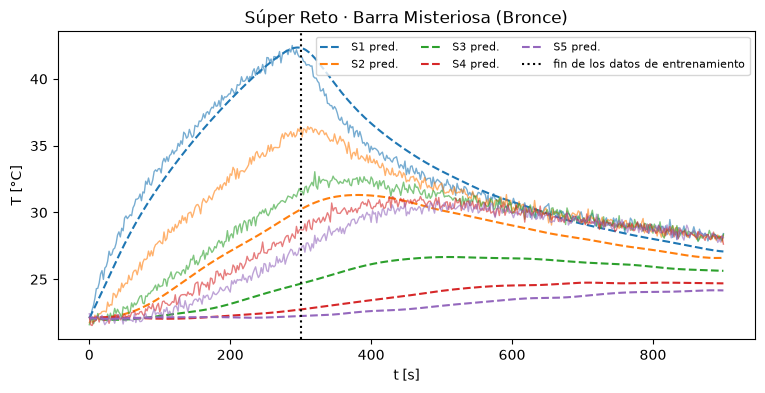

RMSE [°C] por ventanas de 150 s: [1.87 4.25 5.49 4.8  3.82 3.06]


In [ ]:

# SÚPER RETO (a): LA BARRA MISTERIOSA

# 1. Realizar el ensayo con la barra misteriosa
CSV_mist = planta_virtual.ensayo(PAREJA, misterio=True)
datos_mist = cargar_ensayo(CSV_mist)

# 2. Identificar alpha y h con 3 semillas para estimar la incertidumbre
s0_mist = amplitud_fuente(datos_mist)
res_mist = []

print("Entrenando problema inverso sobre la barra misteriosa...")
for s in [0, 1, 2]:
    pinn_m = PINN(inverso=True, a=0.5, b=0.5, s0=s0_mist, seed=s)
    entrenar(pinn_m, datos_mist, n_adam=3000, n_lbfgs=250)
    a_id, h_id = pinn_m.parametros()
    res_mist.append((a_id, h_id))
    print(f"Semilla {s} -> alpha: {a_id:.3e} m²/s, h: {h_id:.3e} 1/s")

alphas_m = np.array([r[0] for r in res_mist])
hs_m = np.array([r[1] for r in res_mist])

alpha_mean = alphas_m.mean()
alpha_std = alphas_m.std()

print("\n" + "="*50)
print(f"Alpha identificado: {alpha_mean:.3e} ± {alpha_std:.3e} m²/s")
print(f"h identificado:     {hs_m.mean():.3e} ± {hs_m.std():.3e} 1/s")
print("="*50)

# 3. Clasificación del material según la tabla de referencia
tabla_metales = {
    "Cobre": 1.1e-4,
    "Aluminio": 9.7e-5,
    "Latón": 3.4e-5,
    "Bronce": 1.9e-5,
    "Acero al carbono": 1.2e-5,
    "Acero inoxidable": 4.0e-6
}

metal_detectado = min(tabla_metales.keys(), key=lambda m: abs(tabla_metales[m] - alpha_mean))
print(f"\n-> Metal identificado: {metal_detectado} (valor teórico: {tabla_metales[metal_detectado]:.2e} m²/s)")

# 4. Gráfica de ajuste del sensor virtual y curvas
rmse_mist = comparar(pinn_m, f"Súper Reto · Barra Misteriosa ({metal_detectado})")

#ANIMACION


In [24]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML
from matplotlib.animation import FuncAnimation

# Cargar la simulación física de referencia
T_campo = np.load("data/campo_base.npy")
x_malla = np.load("data/x_malla.npy")
t_segundos = np.linspace(0, 900, T_campo.shape[0])

# Configurar la ventana gráfica
fig, ax = plt.subplots(figsize=(8, 4))
(line,) = ax.plot([], [], lw=2.5, color="#d95f02", label="Perfil térmico")
ax.set_xlim(0, 30)
ax.set_ylim(20, 50)
ax.set_xlabel("Posición en la barra x [cm]")
ax.set_ylabel("Temperatura [°C]")
ax.grid(True, linestyle="--", alpha=0.6)
ax.axvspan(0, 2, color="orange", alpha=0.2, label="Resistencia (0-2 cm)")
ax.legend(loc="upper right")
texto_tiempo = ax.text(
    0.05, 0.90, "", transform=ax.transAxes, fontsize=11, weight="bold"
)


def init():
  line.set_data([], [])
  texto_tiempo.set_text("")
  return line, texto_tiempo


def update(frame):
  idx = frame * 4  # Salto de fotogramas para velocidad óptima
  line.set_data(x_malla * 100, T_campo[idx, :])
  estado_res = "ON" if t_segundos[idx] <= 300 else "OFF"
  texto_tiempo.set_text(
      f"t = {t_segundos[idx]:.0f} s | Resistencia: {estado_res}"
  )
  return line, texto_tiempo


# Generar y mostrar la animación con barra de reproducción
anim = FuncAnimation(
    fig,
    update,
    init_func=init,
    frames=len(t_segundos) // 4,
    interval=40,
    blit=True,
)
plt.close(fig)
HTML(anim.to_jshtml())